In [1]:
import torch
import torch.nn as nn
from torch.nn.utils import spectral_norm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import linear_sum_assignment

In [2]:
SEED = 42
DEVICE = 'mps'

batch_size = 128
lr = 1e-3
eps_max = 0.05

emm_phase1_steps = 5_000
emm_phase2_steps = 500
cd_weight = 1e-3

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

In [4]:
def sample_noise(batch_size):
    return torch.randn(batch_size, 1, 28, 28)

train_iter = iter(train_loader)
def sample_data(batch_size):
    global train_iter
    try:
        return next(train_iter)[0]
    except StopIteration:
        train_iter = iter(train_loader)
        return next(train_iter)[0]

In [5]:
def plot_losses(losses, color = 'tab:blue'):
    fig, ax = plt.subplots()

    ax.plot(losses, label="Loss", color=color, alpha=0.5)
    ws = 100
    smoothed = np.convolve(losses, np.ones(ws)/ws, mode="valid")
    ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed Loss", color=color)

    plt.legend()
    plt.grid()
    plt.show()

def plot_samples(x, n_cols=8, figsize_scale=1.2):
    # x = x.detach().cpu().view(-1, 28, 28)  # (N, 784) -> (N, 28, 28)
    x = x.detach().cpu().squeeze(1)  
    n = x.shape[0]
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_scale, n_rows * figsize_scale))
    axes = axes.flatten() if n > 1 else [axes]

    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(x[i], cmap="gray")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [6]:
class EnergyMatchingCNN(nn.Module):
    def __init__(self, in_ch=1, base_ch=32, hidden_dim=512, output_scale=200.0):
        super().__init__()

        self.output_scale = output_scale

        self.conv = nn.Sequential(
            spectral_norm(nn.Conv2d(in_ch, base_ch, 3, padding=1)),
            nn.SiLU(),
            spectral_norm(nn.Conv2d(base_ch, base_ch, 3, padding=1)),
            nn.SiLU(),
            nn.AvgPool2d(2),
            spectral_norm(nn.Conv2d(base_ch, base_ch * 2, 3, padding=1)),
            nn.SiLU(),
            spectral_norm(nn.Conv2d(base_ch * 2, base_ch * 2, 3, padding=1)),
            nn.SiLU(),
            nn.AvgPool2d(2),
        )

        self.head = nn.Sequential(
            nn.Flatten(),
            spectral_norm(nn.Linear(base_ch * 2 * 7 * 7, hidden_dim)),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.head(self.conv(x)).squeeze(-1) * self.output_scale  # shape: (B,)

In [7]:
def ot_couple(x0, x1):
    cost = torch.cdist(x0.flatten(1), x1.flatten(1)) ** 2
    row_ind, col_ind = linear_sum_assignment(cost.cpu().detach().numpy())

    return x0[row_ind], x1[col_ind]

def grad_V(V, x):
    x = x.detach().requires_grad_(True)
    energy = V(x)
    grad = torch.autograd.grad(
        energy.sum(),
        x,
        create_graph=True
    )[0]
    return grad, energy

def langevin_negative_samples(V, x_int, n_steps = 20, step_size = 0.01, eps_max = 0.05):
    x = x_int.clone().detach()
    for _ in range(n_steps):
        g, _ = grad_V(V, x)
        noise = torch.randn_like(x)

        x = x - step_size * g + (2 * step_size * eps_max) ** 0.5 * noise
        x = x.detach()

    return x

# def ode_integrate(V, x, n_steps=50, dt=None):
#     dt = dt if dt is not None else 1.0 / n_steps
#     x = x.clone().detach()
#     for _ in range(n_steps):
#         x = x.requires_grad_(True)
#         energy = V(x).sum()
#         (g,) = torch.autograd.grad(energy, x)  # no create_graph needed here
#         x = x.detach() - dt * g.detach()
#     return x

def ode_integrate(V, x, tau_s=2.0, dt=0.025, eps_max=0.1, tau_star=1.0):
    x = x.clone().detach()
    t = 0.0
    n_steps = int(tau_s / dt)
    
    for _ in range(n_steps):
        x = x.requires_grad_(True)
        energy = V(x).sum()
        g = torch.autograd.grad(energy, x)[0].detach()
        x = x.detach()
        
        # Temperature schedule: 0 before tau_star, ramps up after
        eps = 0.0
        if t >= tau_star:
            eps = eps_max * (t - tau_star) / (1.0 - tau_star) if t < 1.0 else eps_max
        
        noise = torch.randn_like(x)
        x = x - dt * g + (2 * dt * eps) ** 0.5 * noise
        t += dt
    
    return x

def phase1_loss(V, x_0, x_1, t):
    x_0, x_1 = ot_couple(x_0, x_1)
    x_t = ((1 - t) * x_0 + t * x_1).detach().requires_grad_(True)
    target = x_0 - x_1

    # Normalize target to unit vectors, scale pred to match
    target_norm = target.flatten(1).norm(dim=1, keepdim=True)  # (B, 1)
    target_normalized = target / target_norm.view(-1, 1, 1, 1).clamp(min=1e-6)

    pred, _ = grad_V(V, x_t)
    pred_normalized = pred / target_norm.view(-1, 1, 1, 1).clamp(min=1e-6)

    return ((pred_normalized - target_normalized) ** 2).mean()

def phase2_loss(V, x_0, x_1, t, eps_max = 0.05, cd_weight = 1.0, alpha=0.1):
    ot_loss = phase1_loss(V, x_0, x_1, t)

    half = x_1.shape[0] // 2
    x_0 = x_0[:half]
    x0_pushed = ode_integrate(V, x_0)
    x_init = torch.cat([x_1[:half] + 0.1 * torch.randn_like(x_1[:half]), x0_pushed], dim=0)

    x_neg = langevin_negative_samples(V, x_init, eps_max=eps_max)

    v_data = V(x_1)
    v_neg = V(x_neg)

    cd_loss = v_data.mean() / eps_max - v_neg.mean() / eps_max
    reg = alpha * (v_data ** 2 + v_neg ** 2).mean()

    return ot_loss + cd_weight * cd_loss + reg


In [8]:
emm = EnergyMatchingCNN().to(DEVICE)
optimizer = torch.optim.Adam(emm.parameters(), lr)

In [9]:
# Remove torch.no_grad() — we need the graph for input gradients
x_test = sample_data(32).to(DEVICE)
x_test = x_test.detach().requires_grad_(True)
v = emm(x_test)
g = torch.autograd.grad(v.sum(), x_test)[0]
print(f"V magnitude: {v.abs().mean():.3f}")
print(f"∇V magnitude: {g.flatten(1).norm(dim=1).mean():.3f}")
print(f"needed output_scale multiplier: {38 / g.flatten(1).norm(dim=1).mean():.1f}x")

V magnitude: 6.695
∇V magnitude: 0.281
needed output_scale multiplier: 135.2x


100%|██████████| 5000/5000 [04:49<00:00, 17.28it/s, Loss=0.00016593]


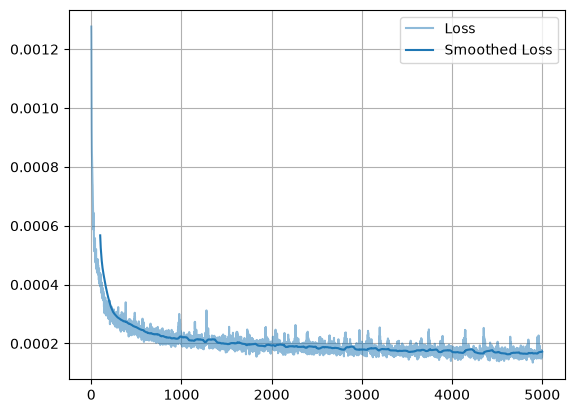

In [10]:
emm.train()
phase1_losses = []
with tqdm(range(emm_phase1_steps)) as pb:
    for i in pb:
        x_0 = sample_noise(batch_size).to(DEVICE)
        x_1 = sample_data(batch_size).to(DEVICE)
        t = torch.rand(x_0.shape[0], 1, 1, 1, device=DEVICE)

        optimizer.zero_grad()
        loss = phase1_loss(emm, x_0, x_1, t)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(emm.parameters(), max_norm=1.0)
        optimizer.step() 

        pb.set_postfix({'Loss': f'{loss.item():.8f}'})
        phase1_losses.append(loss.item())

plot_losses(phase1_losses, color='tab:blue')


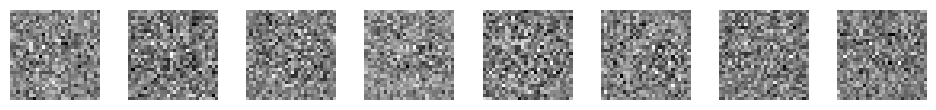

In [18]:
emm.eval()
x_0 = sample_noise(8).to(DEVICE)

# Phase 1 only
samples = ode_integrate(emm, x_0)

plot_samples(samples)

100%|██████████| 500/500 [03:55<00:00,  2.12it/s, Loss=17.10]     


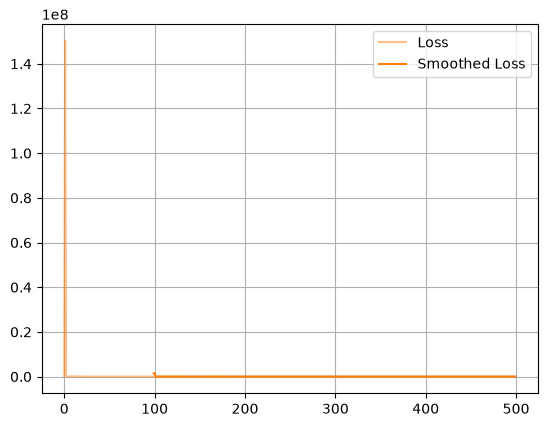

In [12]:
emm.train()
phase2_losses = []
with tqdm(range(emm_phase2_steps)) as pb:
    for i in pb:
        x_0 = sample_noise(batch_size).to(DEVICE)
        x_1 = sample_data(batch_size).to(DEVICE)
        t = torch.rand(x_0.shape[0], 1, 1, 1, device=DEVICE)

        optimizer.zero_grad()
        loss = phase2_loss(emm, x_0, x_1, t, eps_max, cd_weight, alpha=0.3)
        loss.backward()
        optimizer.step() 

        pb.set_postfix({'Loss': f'{loss.item():.2f}'})
        phase2_losses.append(loss.item())


plot_losses(phase2_losses, color='tab:orange')

In [15]:

def sample_emm(V, x_0, ode_steps = 50, langevin_steps = 10, eps_max = 0.05):
    x = x_0
    with torch.enable_grad():
        x = ode_integrate(V, x)
        x = langevin_negative_samples(V, x, n_steps=langevin_steps, eps_max=eps_max)

    return x

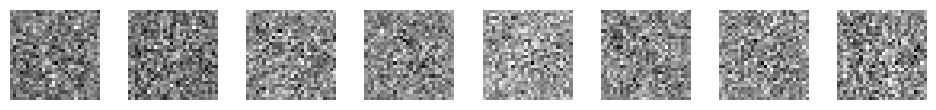

In [16]:
emm.eval()
x_0 = sample_noise(8).to(DEVICE)

samples = sample_emm(emm, x_0, ode_steps=50, langevin_steps=10, eps_max=eps_max).cpu()
plot_samples(samples)